# DC4 versus Pascal NF: temporal background stability

This notebook presents a direct comparison of the completed stability analyses in notebooks 03 and 04. It loads only their compact exported results; it does not open either event file and does not repeat the SAA selection, histogram accumulation, or stability calculations.

The exported products preserve the common time intervals, CDS bins, normalized histograms, leave-one-out differences, TVD series, counting-noise series, and SAA-phase results. No cut, smoothing, reweighting, or alignment is applied here.

In [1]:
%load_ext autoreload
%autoreload 2

## 1. Load the exported stability products

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import numpy as np
import pandas as pd

plt.style.use("seaborn-v0_8-whitegrid")
SOURCE_COLORS = {"DC4": "#0072B2", "Pascal NF": "#D55E00"}

In [3]:
result_paths = {
    "DC4": Path("../data/total_background/dc4_stability_results.npz"),
    "Pascal NF": Path("../data/NF_background/pascal_nf_stability_results.npz"),
}
missing = [str(path) for path in result_paths.values() if not path.exists()]
assert not missing, f"Run the final export cells in notebooks 03 and 04 first: {missing}"

In [4]:
def load_export(path):
    with np.load(path, allow_pickle=False) as file:
        return {name: file[name] for name in file.files}

results = {source: load_export(path) for source, path in result_paths.items()}
projection_names = results["DC4"]["projection_names"].tolist()
metric_names = [*projection_names, "Joint 4D"]

### Comparability checks

The assertions below prevent presentation if the exports do not share the established time grid, projection names, bin edges, summary schema, or 10-minute SAA windows. They do not alter either result.

In [5]:
dc4, nf = results["DC4"], results["Pascal NF"]
for key in ["time_edges", "midpoint_days", "group_days", "group_livetime",
            "projection_names", "summary_names", "summary_columns"]:
    np.testing.assert_allclose(dc4[key], nf[key]) if np.issubdtype(dc4[key].dtype, np.number) else np.testing.assert_array_equal(dc4[key], nf[key])
for name in projection_names:
    np.testing.assert_allclose(dc4[f"{name.lower()}_edges"], nf[f"{name.lower()}_edges"])
assert int(dc4["saa_window_seconds"]) == int(nf["saa_window_seconds"]) == 600
print(f"Validated {len(dc4['midpoint_days'])} common time intervals and {len(projection_names)} common CDS projections.")

Validated 14 common time intervals and 4 common CDS projections.


## 2. Compact metric summary

In [6]:
summary_tables = {}
for source, data in results.items():
    summary_tables[source] = pd.DataFrame(data["summary_values"], index=data["summary_names"], columns=data["summary_columns"])
comparison_summary = pd.concat(summary_tables, names=["Source", "CDS projection"])
comparison_summary.style.format("{:.6f}").set_caption("Long-term normalized-shape comparison")

## 3. Background-rate evolution

The upper panel is the direct rate overlay. The lower panel shows $(R_{\mathrm{NF}}-R_{\mathrm{DC4}})/R_{\mathrm{DC4}}$ only as a presentation of their agreement; it is not used in any shape normalization. The first 7-day interval is shaded.

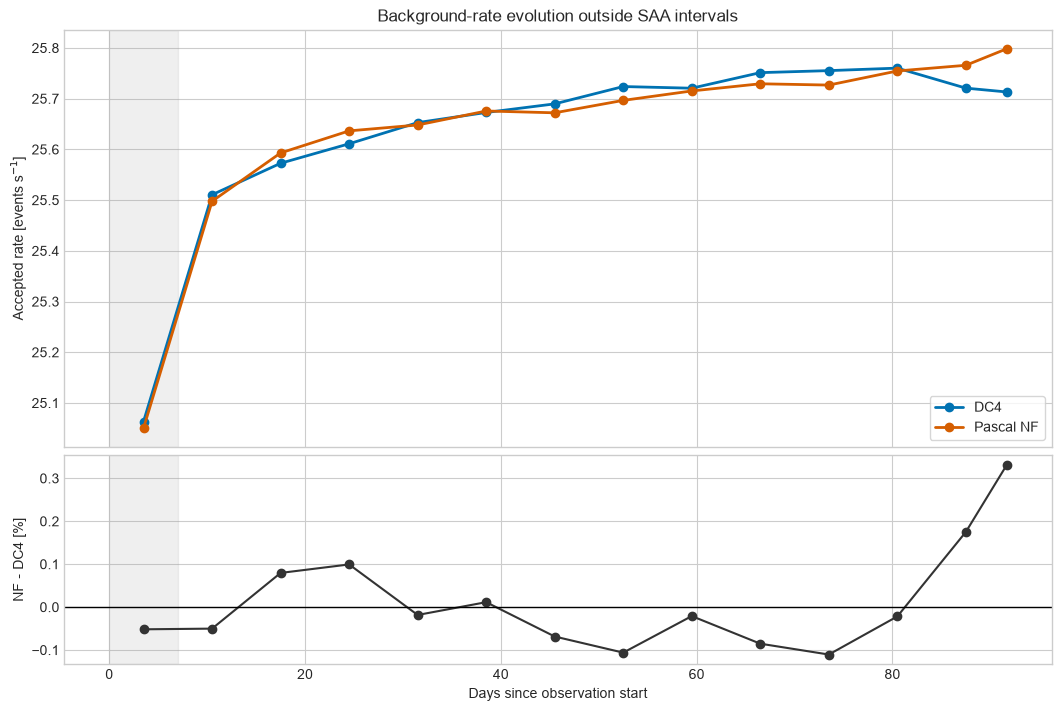

,Day,DC4,Pascal NF,Difference [%]
0,3.500000,25.063362,25.050379,-0.051803
1,10.500000,25.510514,25.497708,-0.050201
2,17.500000,25.572643,25.592989,0.079562
3,24.500000,25.611057,25.636501,0.099347
4,31.500000,25.652805,25.648086,-0.018395
5,38.500000,25.672775,25.675710,0.011432
6,45.500000,25.689750,25.672126,-0.068601
7,52.500000,25.723922,25.696616,-0.106147
8,59.500000,25.720622,25.715219,-0.021006
9,66.500000,25.751339,25.729371,-0.085310


In [7]:
midpoint_days = dc4["midpoint_days"]
elapsed_edges = (dc4["time_edges"] - dc4["time_edges"][0]) / 86400
rate_difference = 100 * (nf["rate_per_second"] - dc4["rate_per_second"]) / dc4["rate_per_second"]
fig, axes = plt.subplots(2, 1, figsize=(10.5, 7), sharex=True, height_ratios=[2, 1], layout="constrained")
for source, data in results.items():
    axes[0].plot(midpoint_days, data["rate_per_second"], marker="o", linewidth=2, color=SOURCE_COLORS[source], label=source)
axes[1].plot(midpoint_days, rate_difference, marker="o", color="#333333")
axes[1].axhline(0, color="black", linewidth=1)
for ax in axes:
    ax.axvspan(elapsed_edges[0], elapsed_edges[1], color="#999999", alpha=0.15)
axes[0].set(ylabel="Accepted rate [events s$^{-1}$]", title="Background-rate evolution outside SAA intervals")
axes[1].set(xlabel="Days since observation start", ylabel="NF - DC4 [%]")
axes[0].legend(frameon=True)
plt.show()
pd.DataFrame({"Day": midpoint_days, "DC4": dc4["rate_per_second"], "Pascal NF": nf["rate_per_second"], "Difference [%]": rate_difference})

**Interpretation.** Both rates start near 25.05 events/s and rise rapidly during the early intervals before flattening near 25.7–25.8 events/s. Their interval-by-interval differences remain sub-percent. The NF therefore reproduces the overall DC4 amplitude evolution, including the distinct lower-rate first interval.

## 4. Direct TVD evolution

Every panel overlays the saved leave-one-out TVD series. Values are percentages of redistributed normalized probability. The shaded band again marks the first interval.

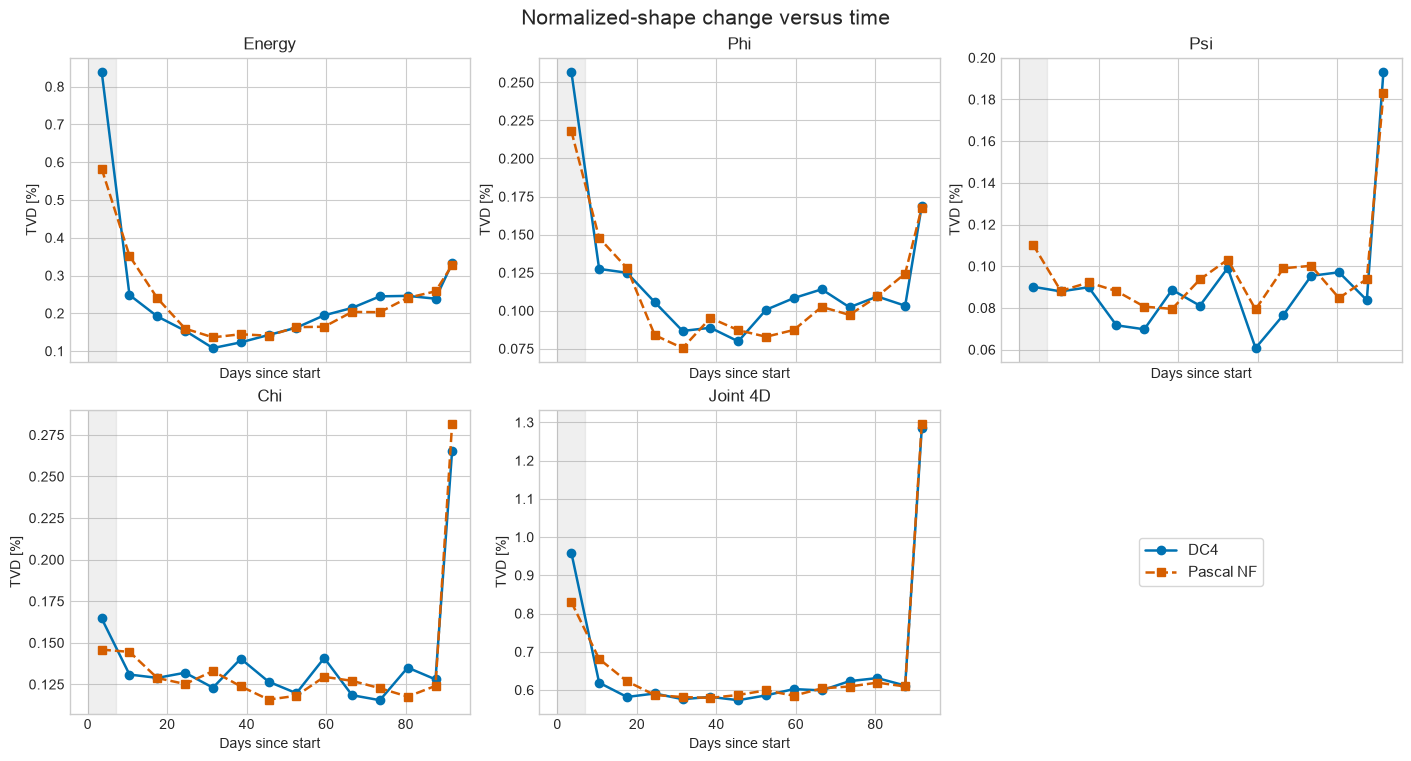

,Energy TVD [%],Phi TVD [%],Psi TVD [%],Chi TVD [%],Joint 4D TVD [%]
DC4,0.8398,0.2572,0.0902,0.1646,0.9593
Pascal NF,0.5827,0.2181,0.1104,0.1459,0.8301


In [8]:
metric_keys = {"Energy": "energy", "Phi": "phi", "Psi": "psi", "Chi": "chi", "Joint 4D": "joint"}
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5), sharex=True, layout="constrained")
for ax, name in zip(axes.flat, metric_names):
    key = metric_keys[name]
    for source, data, marker, linestyle in [("DC4", dc4, "o", "-"), ("Pascal NF", nf, "s", "--")]:
        ax.plot(midpoint_days, 100 * data[f"{key}_tvd"], marker=marker, linestyle=linestyle, linewidth=1.8, color=SOURCE_COLORS[source], label=source)
    ax.axvspan(elapsed_edges[0], elapsed_edges[1], color="#999999", alpha=0.15)
    ax.set(title=name, xlabel="Days since start", ylabel="TVD [%]")
axes[1, 2].axis("off")
handles, labels = axes[0, 0].get_legend_handles_labels()
axes[1, 2].legend(handles, labels, loc="center", frameon=True, fontsize=11)
fig.suptitle("Normalized-shape change versus time", fontsize=15)
plt.show()
early_time = pd.DataFrame({source: {f"{name} TVD [%]": 100 * data[f"{metric_keys[name]}_tvd"][0] for name in metric_names} for source, data in results.items()}).T
early_time.style.format("{:.4f}").set_caption("First 7-day interval")

**Interpretation.** Both sources identify energy as the strongest statistically resolved long-term marginal variation and `Phi` as the next strongest. The NF maximum TVD is smaller for energy (0.00583 versus 0.00840) and `Phi` (0.00218 versus 0.00257), while the joint 4D maxima are nearly identical (0.01297 versus 0.01285). The early-time table tests whether the most prominent first-interval behavior occurs in both without shifting their time axes.

## 5. Side-by-side normalized CDS projections

Each colored line is one saved, independently normalized time interval; black is the all-time distribution reconstructed from the exported count histograms. Matching axes are enforced within each row. The common color scale represents time-group midpoint.

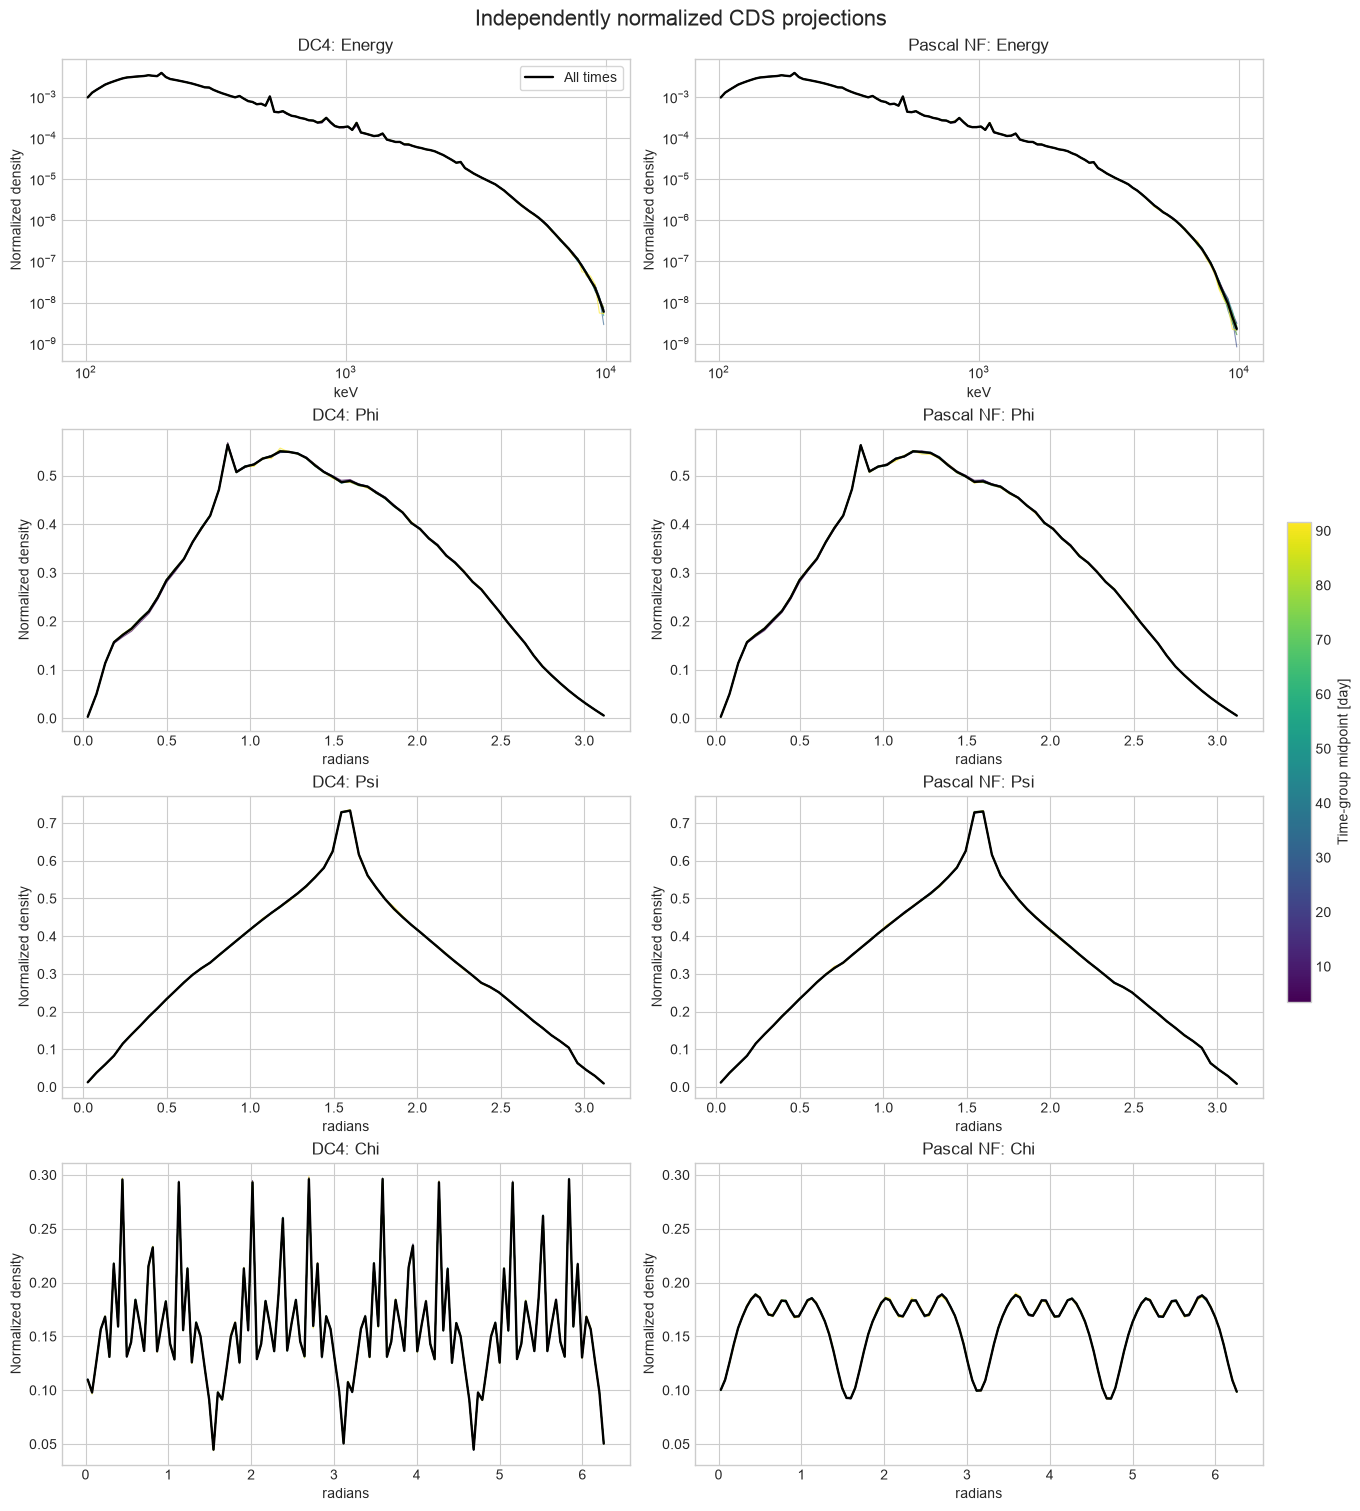

In [9]:
fig, axes = plt.subplots(4, 2, figsize=(13.5, 15), layout="constrained")
time_norm, time_cmap = Normalize(midpoint_days.min(), midpoint_days.max()), plt.cm.viridis
for row, name in enumerate(projection_names):
    key, edges = name.lower(), dc4[f"{name.lower()}_edges"]
    centers = np.sqrt(edges[:-1] * edges[1:]) if name == "Energy" else (edges[:-1] + edges[1:]) / 2
    for column, (source, data) in enumerate(results.items()):
        ax, density = axes[row, column], data[f"{key}_density"]
        for group, midpoint in enumerate(midpoint_days):
            ax.plot(centers, density[group], color=time_cmap(time_norm(midpoint)), alpha=0.65, linewidth=0.8)
        counts = data[f"{key}_counts"]
        pooled = counts.sum(axis=0) / counts.sum() / np.diff(edges)
        ax.plot(centers, pooled, color="black", linewidth=1.7, label="All times")
        ax.set(title=f"{source}: {name}", xlabel="keV" if name == "Energy" else "radians", ylabel="Normalized density")
        if name == "Energy": ax.set(xscale="log", yscale="log")
    limits = min(axes[row, 0].get_ylim()[0], axes[row, 1].get_ylim()[0]), max(axes[row, 0].get_ylim()[1], axes[row, 1].get_ylim()[1])
    axes[row, 0].set_ylim(limits); axes[row, 1].set_ylim(limits)
axes[0, 0].legend(frameon=True)
fig.colorbar(plt.cm.ScalarMappable(norm=time_norm, cmap=time_cmap), ax=axes, label="Time-group midpoint [day]", fraction=0.02, pad=0.02)
fig.suptitle("Independently normalized CDS projections", fontsize=16)
plt.show()

**Interpretation.** Matching axes prevent automatic scaling from exaggerating one source. The strongest colored-line spread is expected in energy and then `Phi`; `Psi` and `Chi` are visibly more stable. Differences between the black all-time curves describe overall NF-versus-DC4 density agreement, not temporal stability.

## 6. Time-resolved difference maps

The maps use the saved $100(p_{i,b}-p_{\mathrm{ref},b})$ arrays. For each CDS coordinate, DC4 and NF share one symmetric linear color scale computed from both exported maps. No smoothing or bin masking is applied.

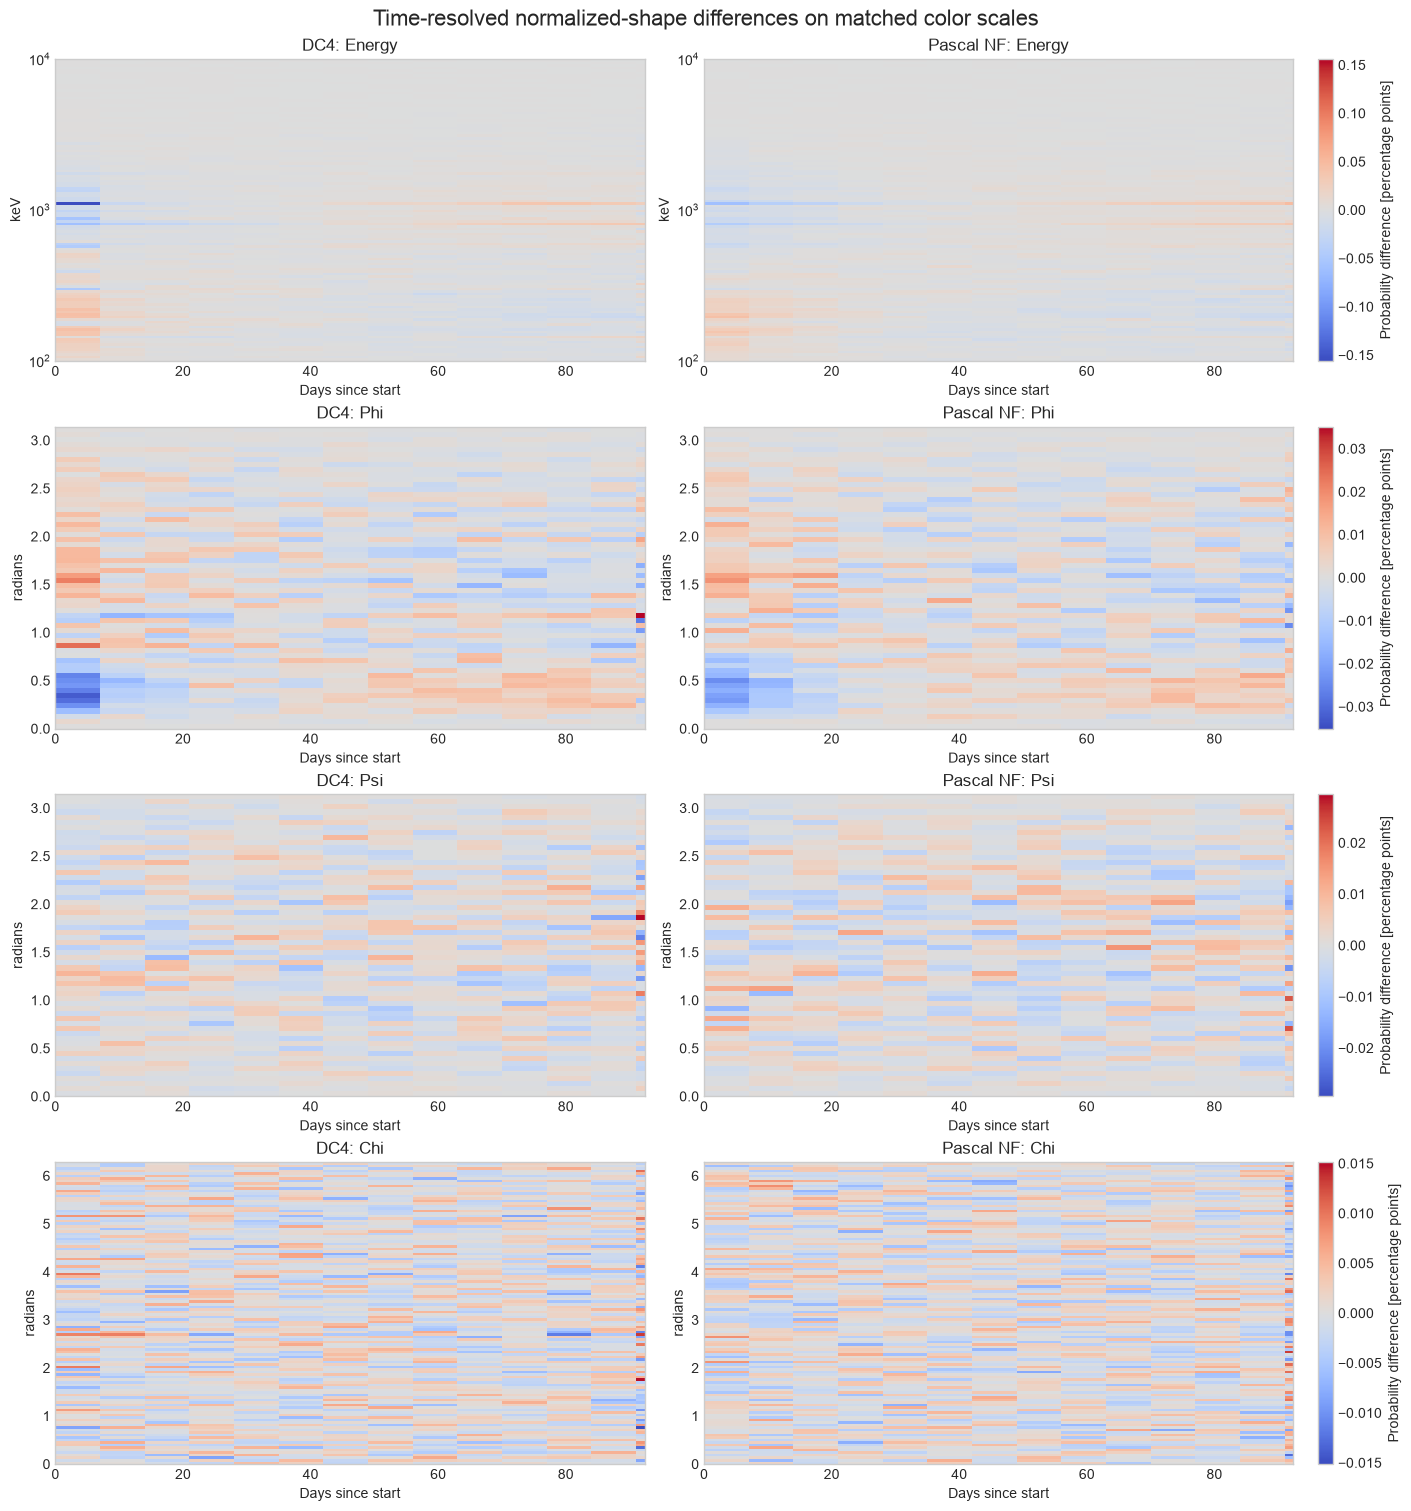

In [10]:
fig, axes = plt.subplots(4, 2, figsize=(14, 15), layout="constrained")
for row, name in enumerate(projection_names):
    key, edges = name.lower(), dc4[f"{name.lower()}_edges"]
    maps = {source: data[f"{key}_difference_pp"] for source, data in results.items()}
    limit = max(np.max(np.abs(values)) for values in maps.values())
    for column, (source, values) in enumerate(maps.items()):
        image = axes[row, column].pcolormesh(elapsed_edges, edges, values.T, shading="auto", cmap="coolwarm", vmin=-limit, vmax=limit)
        axes[row, column].set(title=f"{source}: {name}", xlabel="Days since start", ylabel="keV" if name == "Energy" else "radians")
        if name == "Energy": axes[row, column].set_yscale("log")
    fig.colorbar(image, ax=axes[row, :], label="Probability difference [percentage points]", fraction=0.025, pad=0.02)
fig.suptitle("Time-resolved normalized-shape differences on matched color scales", fontsize=16)
plt.show()

**Interpretation.** Coherent bands reveal the temporal redistribution responsible for the TVD curves; pixel-scale fluctuations are more compatible with counting noise. The shared scale directly shows that the NF reproduces the qualitative DC4 pattern while somewhat reducing the strongest energy variation.

## 7. Direct SAA-phase comparison

The signed curves are the exported normalized probability in the first 10 minutes after SAA minus the final 10 minutes before SAA. The accompanying table compares the established TVD and noise quantities.

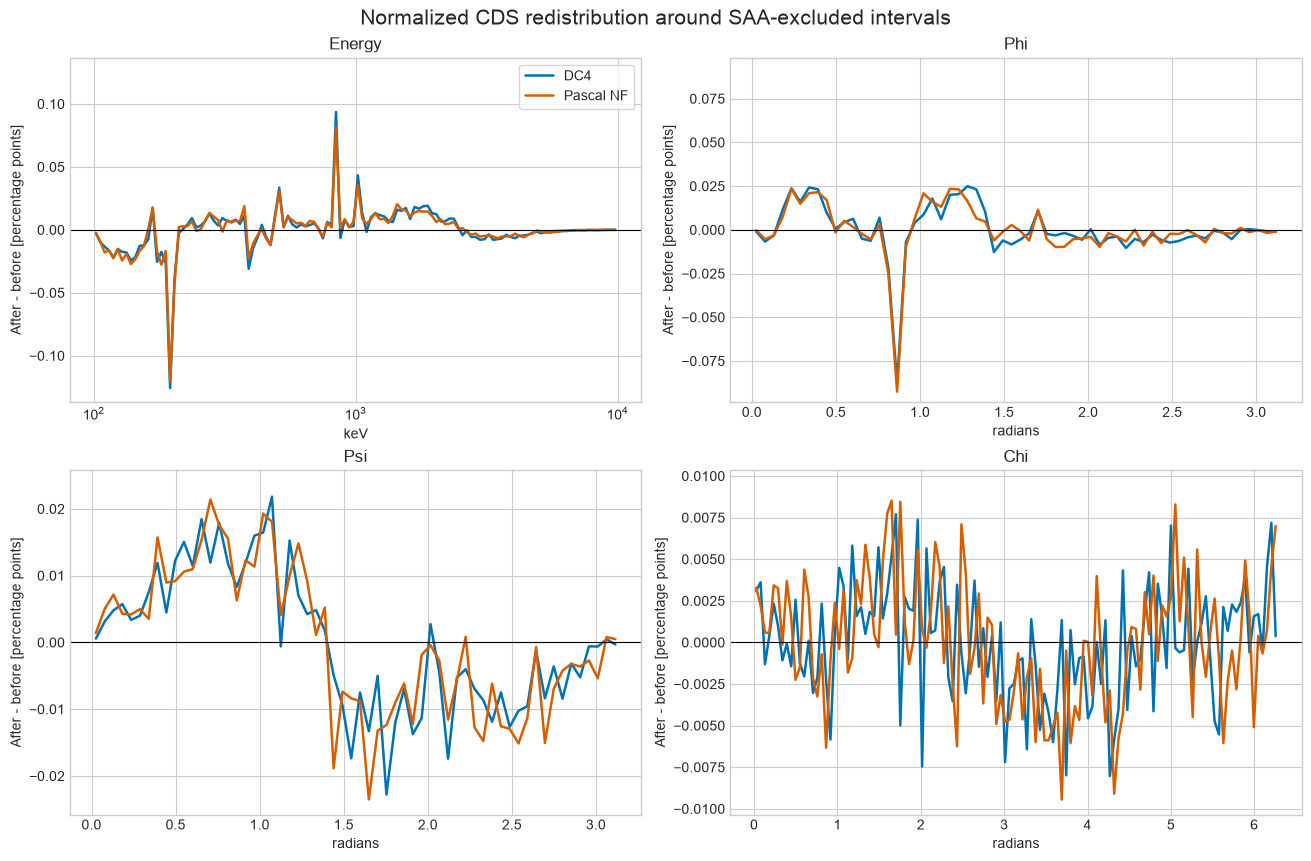

In [11]:
phase_tables = {source: pd.DataFrame(data["phase_metric_values"], index=data["projection_names"], columns=data["phase_metric_columns"]) for source, data in results.items()}
phase_comparison = pd.concat(phase_tables, names=["Source", "CDS projection"])
display(phase_comparison.style.format("{:.6f}").set_caption("First 10 min after SAA versus last 10 min before SAA"))

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), layout="constrained")
for ax, name in zip(axes.flat, projection_names):
    key, edges = name.lower(), dc4[f"{name.lower()}_edges"]
    centers = np.sqrt(edges[:-1] * edges[1:]) if name == "Energy" else (edges[:-1] + edges[1:]) / 2
    for source, data in results.items():
        ax.plot(centers, data[f"{key}_phase_difference_pp"], linewidth=1.8, color=SOURCE_COLORS[source], label=source)
    limit = max(abs(value) for value in ax.get_ylim())
    ax.set_ylim(-limit, limit); ax.axhline(0, color="black", linewidth=0.8)
    ax.set(title=name, xlabel="keV" if name == "Energy" else "radians", ylabel="After - before [percentage points]")
    if name == "Energy": ax.set_xscale("log")
axes[0, 0].legend(frameon=True)
fig.suptitle("Normalized CDS redistribution around SAA-excluded intervals", fontsize=15)
plt.show()

**Interpretation.** The SAA-phase effect sizes are close in the two sources. NF versus DC4 TVD is 0.00583 versus 0.00619 for energy and 0.00261 versus 0.00274 for `Phi`. Both resolve energy, `Phi`, and `Psi` changes relative to counting noise, while `Chi` is weaker. Pascal's time-conditioned sample therefore preserves the main dependence on time relative to SAA passages.

## 8. Scientific summary

DC4 and Pascal NF support the same qualitative conclusion: the CDS shape changes only at the percent level, but the change is statistically resolved and is not strictly time independent. Both identify energy as the dominant long-term variation, followed by `Phi`; their SAA-phase patterns and background-rate evolution are also closely aligned.

The main quantitative difference is that Pascal NF shows weaker maximum long-term changes in energy and `Phi`, while the coarse joint 4D TVD is essentially the same. These differences are small rather than substantial: they change the strength of the resolved variation, not its hierarchy or scientific interpretation.

Therefore a time-independent $P(E_m,\phi,\psi,\chi)$ is not an exact description of either source. It may still be a practical approximation if a downstream analysis demonstrates tolerance to roughly percent-level shape changes. The present comparison cannot establish that tolerance; it shows that any such approximation must be tested especially against energy evolution, early-time behavior, and time relative to SAA.